## FwAI Final Coursework (Student ID: 251057619)

### FwAI Electric Production Forecasting: Model Comparison
**Objective:** Analyse monthly US Electric Production from 1985 to 2018 and forecast future values.

**Models Used:** 
* Statistical: SARIMA, Holt-Winters (Exponential Smoothing)
* Deep Learning: LSTM, 1D CNN

## Environment Setup

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Statistical tools
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Machine Learning / Deep Learning tools
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Conv1D, MaxPooling1D, Flatten

# Plotting style
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = (14, 7)

2026-05-01 23:01:05.647981: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Data Loading & Inspection

                 EP
DATE               
1985-01-01  72.5052
1985-02-01  70.6720
1985-03-01  62.4502
1985-04-01  57.4714
1985-05-01  55.3151


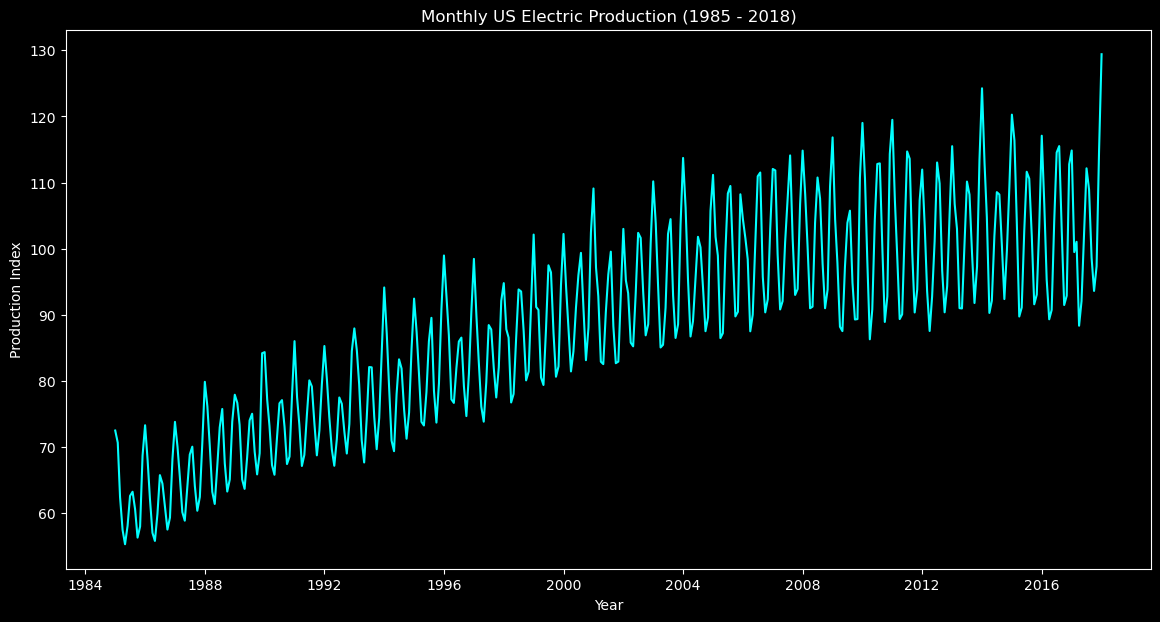

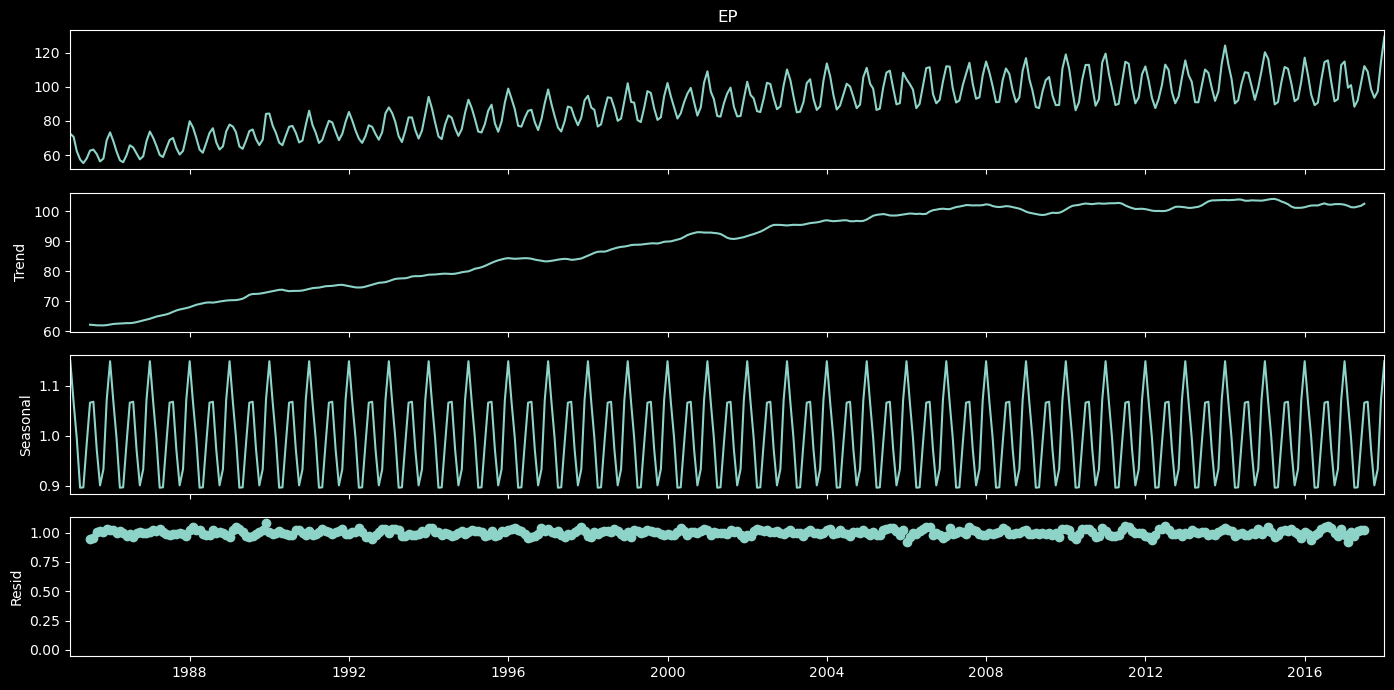

--- Augmented Dickey-Fuller Test ---
ADF Statistic: -2.2570
p-value: 0.1862


In [2]:

df = pd.read_csv('Electric_Production.csv')

df['DATE'] = pd.to_datetime(df['DATE'], format='%m/%d/%Y')

# Set the DATE column as the index (crucial for time series)
df.set_index('DATE', inplace=True)

# frequency to Monthly Start ('MS') to optimise statsmodels
df.index.freq = 'MS'

# Display the first few rows to verify
print(df.head())

# Historical data
plt.plot(df.index, df['EP'], color='cyan')
plt.title('Monthly US Electric Production (1985 - 2018)')
plt.ylabel('Production Index')
plt.xlabel('Year')
plt.grid(False)
plt.show()

# Train-Test Split (Reserve last 36 months for testing)
test_size = 36
train = df.iloc[:-test_size]
test = df.iloc[-test_size:]

# Decomposition to show Trend and Seasonality
decomposition = seasonal_decompose(df['EP'], model='multiplicative')
decomposition.plot()
plt.show()

# Stationarity Test (Augmented Dickey-Fuller)
# Most statistical models require stationary data (constant mean/variance)
print("--- Augmented Dickey-Fuller Test ---")
adf_result = adfuller(df['EP'])
print(f'ADF Statistic: {adf_result[0]:.4f}')
print(f'p-value: {adf_result[1]:.4f}')

# Important note to self: If the p-value is > 0.05, the data is NOT stationary but looking at the plot, there is a clear upward trend and seasonality, so differencing needed!

## Category 1: Statistical Modeling (SARIMA & Holt-Winters)

Training Statistical Models...


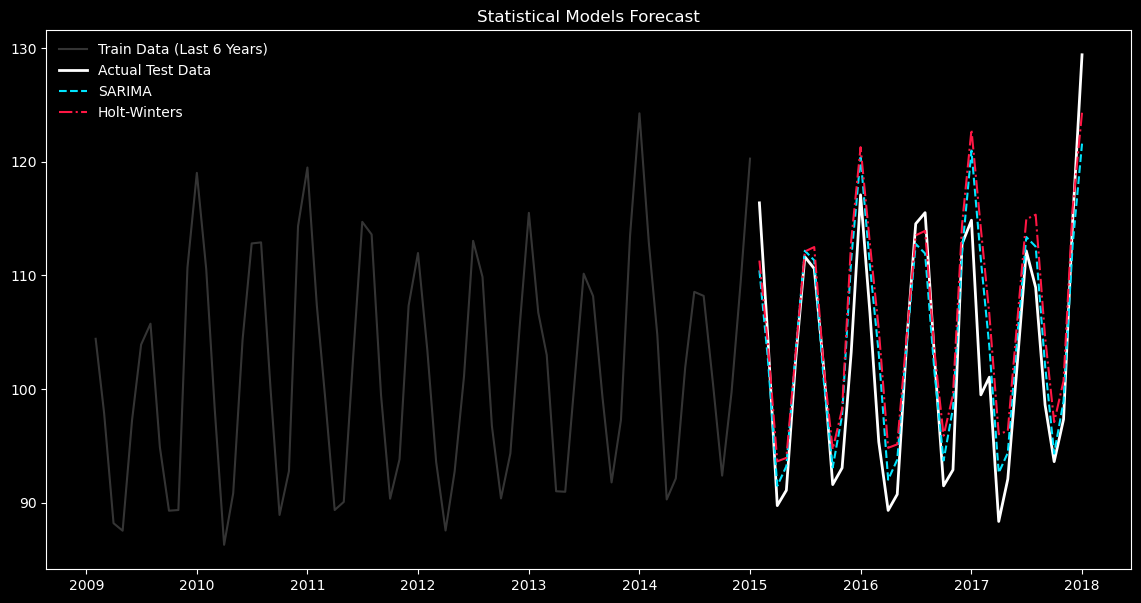

In [3]:
print("Training Statistical Models...")

# SARIMA
sarima_model = SARIMAX(train['EP'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False, enforce_invertibility=False)
sarima_fit = sarima_model.fit(disp=False)
sarima_pred = sarima_fit.get_forecast(steps=len(test)).predicted_mean

# Holt-Winters
hw_model = ExponentialSmoothing(train['EP'], trend='add', seasonal='mul', seasonal_periods=12, initialization_method="estimated")
hw_fit = hw_model.fit()
hw_pred = hw_fit.forecast(steps=len(test))

# Plot Statistical Results
plt.figure(figsize=(14, 7))
plt.plot(train.index[-72:], train['EP'][-72:], label='Train Data (Last 6 Years)', color='dimgrey', alpha=0.5)
plt.plot(test.index, test['EP'], label='Actual Test Data', color='#FFFFFF', linewidth=2)
plt.plot(test.index, sarima_pred, label='SARIMA', color='#00E5FF', linestyle='--')
plt.plot(test.index, hw_pred, label='Holt-Winters', color='#FF1744', linestyle='-.')
plt.title('Statistical Models Forecast', color='white')
plt.legend(frameon=False)
plt.show()

## Category 2: Deep Learning Data Preparation (LSTM)

In [4]:
# Normalize data for Neural Networks
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(train[['EP']])
scaled_test = scaler.transform(test[['EP']])

# Sequence generator function
def create_sequences(data, look_back=12):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0])
        y.append(data[i + look_back, 0])
    return np.array(X), np.array(y)

look_back = 12
X_train, y_train = create_sequences(scaled_train, look_back)
X_test, y_test = create_sequences(scaled_test, look_back)

# Reshape for Keras [samples, time steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

# Align test index for DL models (since they consume 'look_back' points)
dl_test_index = test.index[look_back:]
actuals_for_dl = test['EP'].values[look_back:]

## Category 2: Deep Learning Modeling (LSTM & 1D CNN)

Training Deep Learning Models...


/opt/anaconda3/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/opt/anaconda3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


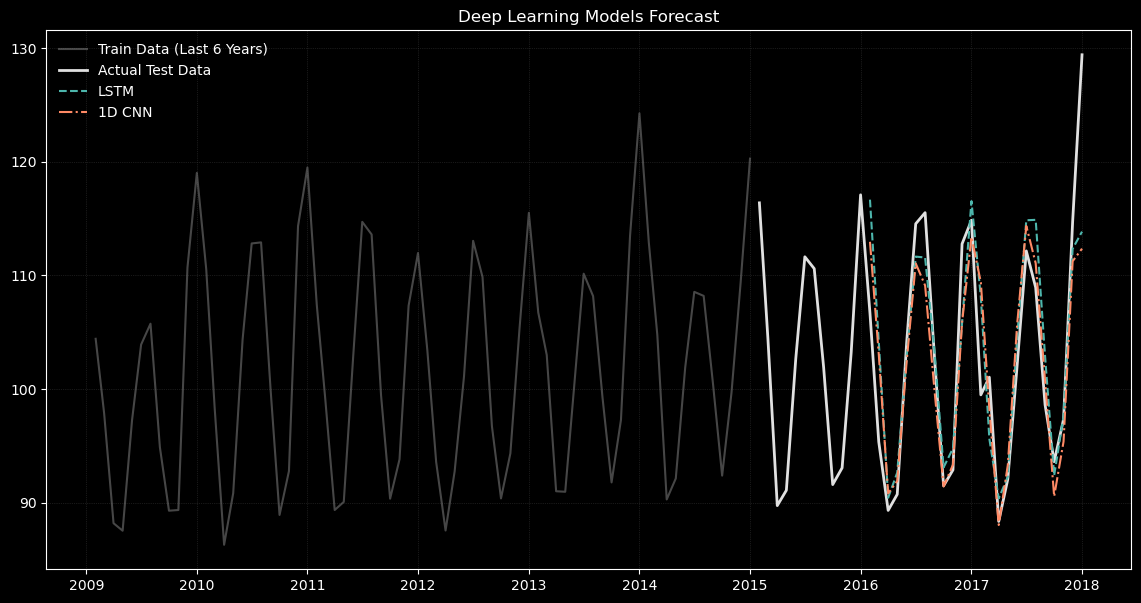

In [5]:
print("Training Deep Learning Models...")

# 3. LSTM
lstm_model = Sequential([
    LSTM(50, activation='relu', input_shape=(look_back, 1)),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.1, verbose=0)

lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()

# 1D CNN
cnn_model = Sequential([
    Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(look_back, 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(50, activation='relu'),
    Dense(1)
])
cnn_model.compile(optimizer='adam', loss='mse')
cnn_model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.1, verbose=0)

cnn_pred_scaled = cnn_model.predict(X_test, verbose=0)
cnn_pred = scaler.inverse_transform(cnn_pred_scaled).flatten()

# Plot Deep Learning Models 
plt.figure(figsize=(14, 7))
plt.plot(train.index[-72:], train['EP'][-72:], label='Train Data (Last 6 Years)',color='#757575', alpha=0.6)
plt.plot(test.index, test['EP'], label='Actual Test Data', color='#E0E0E0', linewidth=2)
plt.plot(dl_test_index, lstm_pred, label='LSTM',color='#4DB6AC', linestyle='--')
plt.plot(dl_test_index, cnn_pred, label='1D CNN',color='#FF8A65', linestyle='-.')
plt.title('Deep Learning Models Forecast')
plt.grid(color='#333333', linestyle=':', linewidth=0.5) # Adds a very subtle grid
plt.legend(frameon=False) # Removes the box around the legend for a cleaner look
plt.show()

## Final Evaluation & Master Comparison Plot

--- FINAL MODEL EVALUATION ---
       Model     RMSE      MAE
      SARIMA 4.109239 3.200382
Holt-Winters 5.252970 4.226350
        LSTM 5.356515 3.898587
      1D CNN 5.273246 3.741983


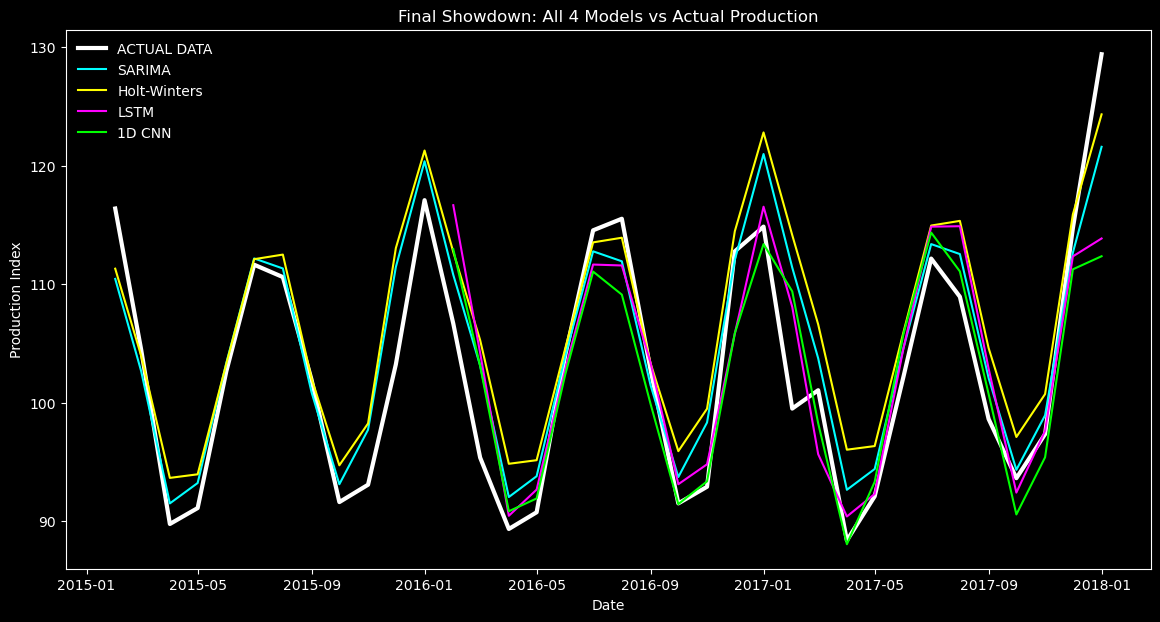

In [6]:
results = pd.DataFrame({
    'Model': ['SARIMA', 'Holt-Winters', 'LSTM', '1D CNN'],
    'RMSE': [
        np.sqrt(mean_squared_error(test['EP'], sarima_pred)),
        np.sqrt(mean_squared_error(test['EP'], hw_pred)),
        np.sqrt(mean_squared_error(actuals_for_dl, lstm_pred)),
        np.sqrt(mean_squared_error(actuals_for_dl, cnn_pred))
    ],
    'MAE': [
        mean_absolute_error(test['EP'], sarima_pred),
        mean_absolute_error(test['EP'], hw_pred),
        mean_absolute_error(actuals_for_dl, lstm_pred),
        mean_absolute_error(actuals_for_dl, cnn_pred)
    ]
})

print("--- FINAL MODEL EVALUATION ---")
print(results.to_string(index=False))

# --- Master Plot ---
plt.figure(figsize=(14, 7))
plt.plot(test.index, test['EP'], label='ACTUAL DATA', color='white', linewidth=3)
plt.plot(test.index, sarima_pred, label='SARIMA', color='cyan')
plt.plot(test.index, hw_pred, label='Holt-Winters', color='yellow')
plt.plot(dl_test_index, lstm_pred, label='LSTM', color='magenta')
plt.plot(dl_test_index, cnn_pred, label='1D CNN', color='lime')
plt.title('Final Showdown: All 4 Models vs Actual Production')
plt.xlabel('Date')
plt.ylabel('Production Index')
plt.legend(frameon=False)
plt.show()